In [2]:
!pip install -q ucimlrepo openpyxl scikit-learn seaborn

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from ucimlrepo import fetch_ucirepo
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
np.random.seed(42)

# Download the official UCI dataset
retail = fetch_ucirepo(id=352)

# Get the original dataset with all columns
df = retail.data.original.copy()

# Standardize column names
df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nFirst five rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (541909, 8)

Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

First five rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom



Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [5]:
# Keep the columns required for RFM
required_columns = [
    "InvoiceNo",
    "InvoiceDate",
    "Quantity",
    "UnitPrice",
    "CustomerID"
]

df = df[required_columns].copy()

# Remove records without a customer ID or required values
df = df.dropna(subset=required_columns)

# Ensure correct data types
df["InvoiceNo"] = df["InvoiceNo"].astype(str)
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"], errors="coerce"
)
df["Quantity"] = pd.to_numeric(
    df["Quantity"], errors="coerce"
)
df["UnitPrice"] = pd.to_numeric(
    df["UnitPrice"], errors="coerce"
)

df["CustomerID"] = pd.to_numeric(
    df["CustomerID"], errors="coerce"
)

df = df.dropna(subset=required_columns)

# Remove cancelled invoices
df = df[~df["InvoiceNo"].str.upper().str.startswith("C")]

# Keep valid purchases
df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

# Customer IDs are identifiers, not numeric measurements
df["CustomerID"] = df["CustomerID"].astype(int)

# Calculate transaction line value
df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]

print("Cleaned dataset shape:", df.shape)
print("Unique customers:", df["CustomerID"].nunique())
print("Unique invoices:", df["InvoiceNo"].nunique())

display(df.head())

Cleaned dataset shape: (397884, 6)
Unique customers: 4338
Unique invoices: 18532


,InvoiceNo,InvoiceDate,Quantity,UnitPrice,CustomerID,TotalAmount
0,536365,2010-12-01 08:26:00,6,2.55,17850,15.30
1,536365,2010-12-01 08:26:00,6,3.39,17850,20.34
2,536365,2010-12-01 08:26:00,8,2.75,17850,22.00
3,536365,2010-12-01 08:26:00,6,3.39,17850,20.34
4,536365,2010-12-01 08:26:00,6,3.39,17850,20.34


In [6]:
# Use one day after the last observed transaction as the reference date
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x:
             (reference_date - x.max()).days),

    Frequency=("InvoiceNo", "nunique"),

    Monetary=("TotalAmount", "sum")
).reset_index()

print("Reference date:", reference_date.date())
print("RFM table shape:", rfm.shape)

display(rfm.head(10))

print("\nRFM descriptive statistics:")
display(rfm[["Recency", "Frequency", "Monetary"]].describe().round(2))

Reference date: 2011-12-10
RFM table shape: (4338, 4)


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40
5,12352,36,8,2506.04
6,12353,204,1,89.00
7,12354,232,1,1079.40
8,12355,214,1,459.40
9,12356,23,3,2811.43



RFM descriptive statistics:


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2054.27
std,100.01,7.70,8989.23
min,1.00,1.00,3.75
25%,18.00,1.00,307.41
50%,51.00,2.00,674.48
75%,142.00,5.00,1661.74
max,374.00,209.00,280206.02


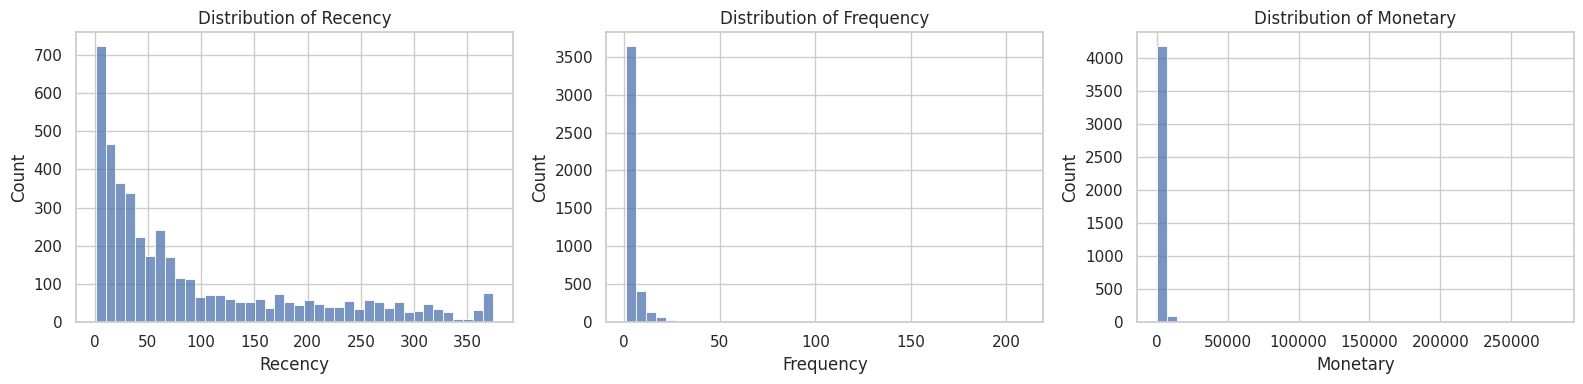

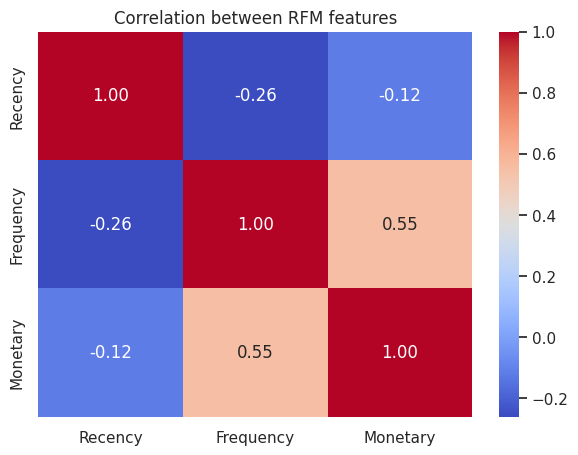

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, col in zip(
    axes, ["Recency", "Frequency", "Monetary"]
):
    sns.histplot(
        data=rfm,
        x=col,
        bins=40,
        ax=ax
    )
    ax.set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.heatmap(
    rfm[["Recency", "Frequency", "Monetary"]]
        .corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation between RFM features")
plt.show()

In [8]:
rfm_features = ["Recency", "Frequency", "Monetary"]

# Log transformation reduces the influence of extreme values
X_log = np.log1p(rfm[rfm_features].astype(float))

# Standardize features so they are on comparable scales
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print("Scaled feature shape:", X_scaled.shape)
print("Mean of scaled features:", X_scaled.mean(axis=0).round(3))
print("Standard deviation:", X_scaled.std(axis=0).round(3))

Scaled feature shape: (4338, 3)
Mean of scaled features: [-0. -0.  0.]
Standard deviation: [1. 1. 1.]


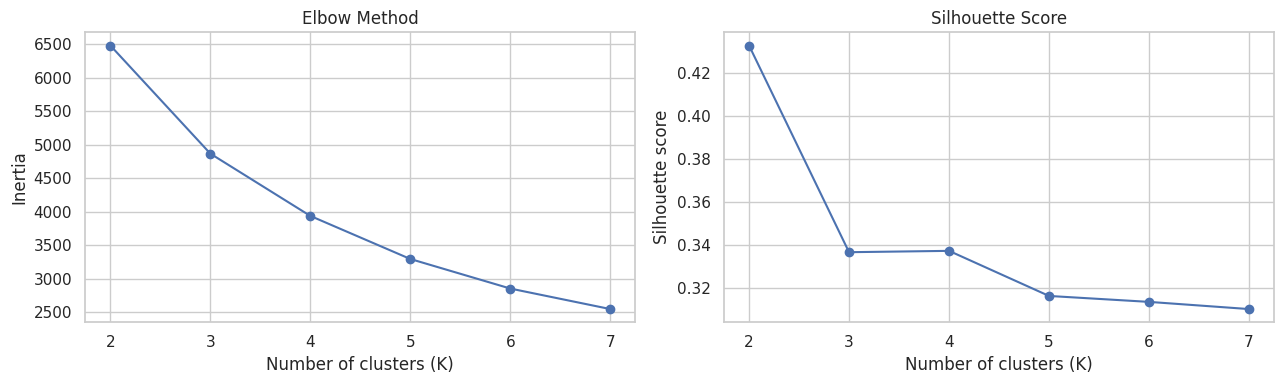

Silhouette scores:
K=2: 0.4329
K=3: 0.3365
K=4: 0.3371
K=5: 0.3161
K=6: 0.3133
K=7: 0.3100
Best K by sampled silhouette score: 2


In [9]:
k_values = range(2, 8)

inertias = []
silhouette_scores = []

for k in k_values:
    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)

    # Sample for faster silhouette calculation on larger datasets
    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=min(5000, len(X_scaled)),
        random_state=42
    )
    silhouette_scores.append(score)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    list(k_values), inertias, marker="o"
)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Inertia")

axes[1].plot(
    list(k_values), silhouette_scores, marker="o"
)
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Silhouette score")

plt.tight_layout()
plt.show()

best_k = list(k_values)[
    int(np.argmax(silhouette_scores))
]

print("Silhouette scores:")
for k, score in zip(k_values, silhouette_scores):
    print(f"K={k}: {score:.4f}")

print("Best K by sampled silhouette score:", best_k)

In [10]:
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

rfm["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print("Customers per K-Means cluster:")
print(
    rfm["KMeans_Cluster"]
    .value_counts()
    .sort_index()
)

print("\nRFM profile by K-Means cluster:")
kmeans_profile = rfm.groupby("KMeans_Cluster")[
    rfm_features
].median().round(2)

display(kmeans_profile)

Customers per K-Means cluster:
KMeans_Cluster
0    2671
1    1667
Name: count, dtype: int64

RFM profile by K-Means cluster:


,Recency,Frequency,Monetary
KMeans_Cluster,,,
0,96.0,1.0,363.88
1,16.0,6.0,2064.95


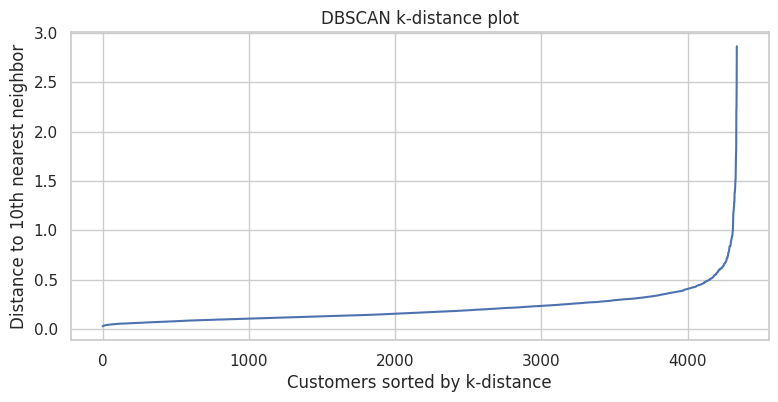

In [11]:
min_samples = 10

neighbors = NearestNeighbors(
    n_neighbors=min_samples
)

neighbors.fit(X_scaled)

distances, _ = neighbors.kneighbors(X_scaled)

# Distance to the kth nearest neighbor
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 4))
plt.plot(k_distances)
plt.title("DBSCAN k-distance plot")
plt.xlabel("Customers sorted by k-distance")
plt.ylabel(f"Distance to {min_samples}th nearest neighbor")
plt.show()

In [12]:
# Initial parameter choice; tune after inspecting the k-distance plot
dbscan = DBSCAN(
    eps=0.8,
    min_samples=min_samples
)

rfm["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)

print("DBSCAN cluster counts:")
print(
    rfm["DBSCAN_Cluster"]
    .value_counts()
    .sort_index()
)

noise_count = (rfm["DBSCAN_Cluster"] == -1).sum()

print("Noise customers:", noise_count)
print(
    f"Noise percentage: "
    f"{100 * noise_count / len(rfm):.2f}%"
)

DBSCAN cluster counts:
DBSCAN_Cluster
-1      29
 0    4309
Name: count, dtype: int64
Noise customers: 29
Noise percentage: 0.67%


Explained variance by components: [0.751  0.1876]
Total variance explained: 0.9386


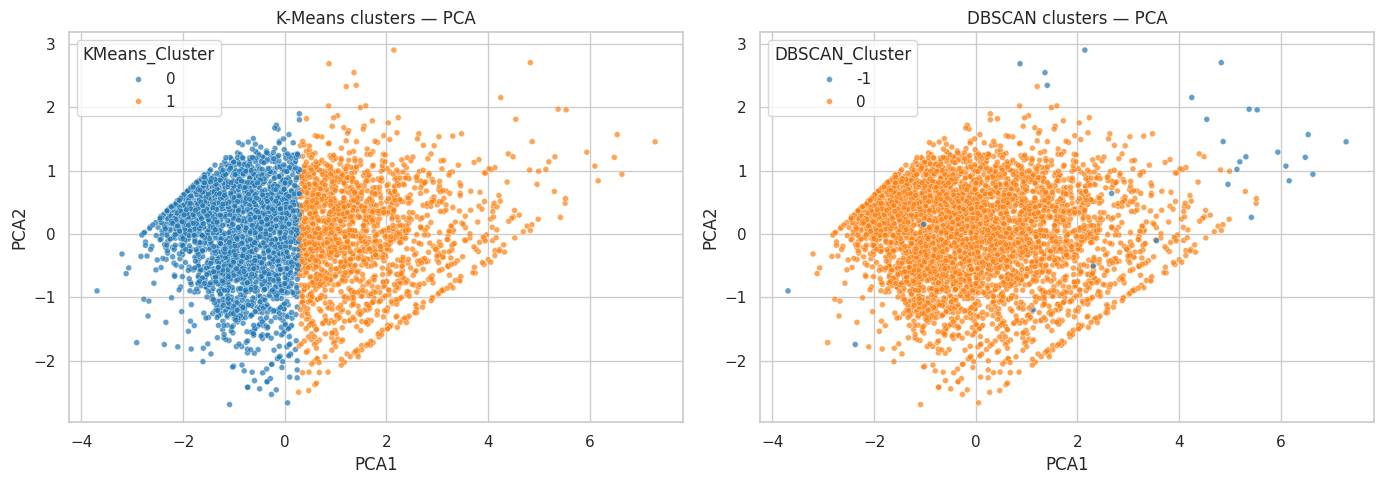

In [13]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

rfm["PCA1"] = X_pca[:, 0]
rfm["PCA2"] = X_pca[:, 1]

print(
    "Explained variance by components:",
    pca.explained_variance_ratio_.round(4)
)
print(
    "Total variance explained:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=rfm,
    x="PCA1",
    y="PCA2",
    hue="KMeans_Cluster",
    palette="tab10",
    s=18,
    alpha=0.7,
    ax=axes[0]
)
axes[0].set_title("K-Means clusters — PCA")

sns.scatterplot(
    data=rfm,
    x="PCA1",
    y="PCA2",
    hue="DBSCAN_Cluster",
    palette="tab10",
    s=18,
    alpha=0.7,
    ax=axes[1]
)
axes[1].set_title("DBSCAN clusters — PCA")

plt.tight_layout()
plt.show()

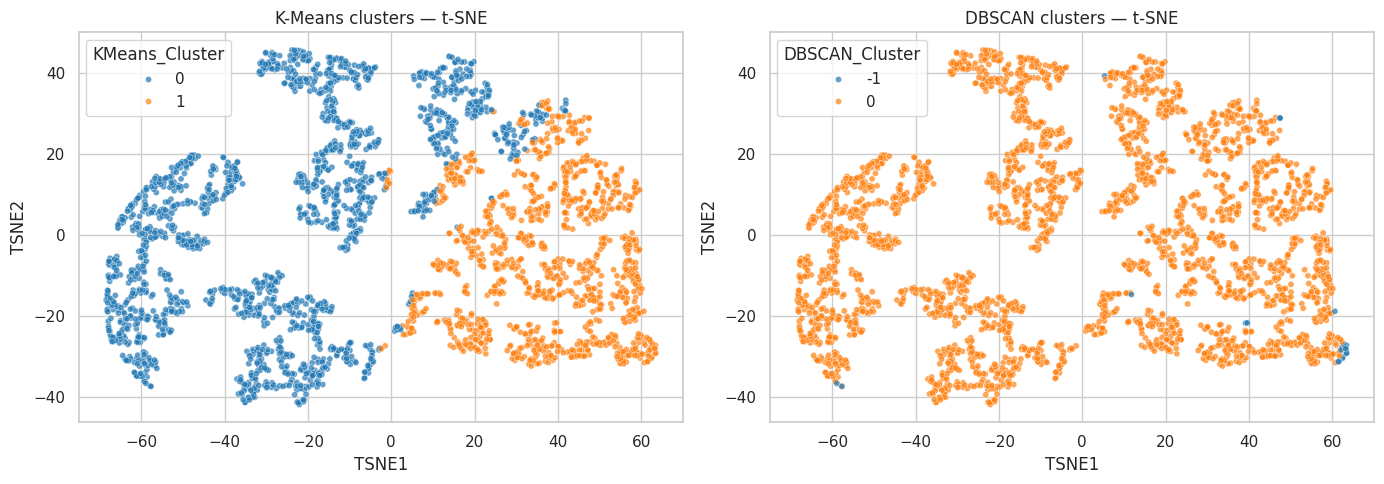

In [14]:
# Use a subset to make t-SNE faster in Colab
sample_size = min(3000, len(rfm))

sample_indices = rfm.sample(
    n=sample_size,
    random_state=42
).index

X_tsne_input = X_scaled[sample_indices]

tsne = TSNE(
    n_components=2,
    perplexity=min(30, max(5, (sample_size - 1) // 3)),
    learning_rate="auto",
    init="pca",
    random_state=42
)

X_tsne = tsne.fit_transform(X_tsne_input)

tsne_df = rfm.loc[
    sample_indices,
    ["KMeans_Cluster", "DBSCAN_Cluster"]
].copy()

tsne_df["TSNE1"] = X_tsne[:, 0]
tsne_df["TSNE2"] = X_tsne[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=tsne_df,
    x="TSNE1",
    y="TSNE2",
    hue="KMeans_Cluster",
    palette="tab10",
    s=20,
    alpha=0.7,
    ax=axes[0]
)
axes[0].set_title("K-Means clusters — t-SNE")

sns.scatterplot(
    data=tsne_df,
    x="TSNE1",
    y="TSNE2",
    hue="DBSCAN_Cluster",
    palette="tab10",
    s=20,
    alpha=0.7,
    ax=axes[1]
)
axes[1].set_title("DBSCAN clusters — t-SNE")

plt.tight_layout()
plt.show()

In [15]:
# K-Means silhouette score
kmeans_silhouette = silhouette_score(
    X_scaled,
    rfm["KMeans_Cluster"],
    sample_size=min(5000, len(rfm)),
    random_state=42
)

# DBSCAN silhouette score, excluding noise
db_labels = rfm["DBSCAN_Cluster"].to_numpy()
non_noise = db_labels != -1
unique_db_clusters = np.unique(db_labels[non_noise])

dbscan_silhouette = np.nan

if (
    len(unique_db_clusters) >= 2
    and non_noise.sum() > len(unique_db_clusters)
):
    dbscan_silhouette = silhouette_score(
        X_scaled[non_noise],
        db_labels[non_noise],
        sample_size=min(5000, non_noise.sum()),
        random_state=42
    )

results = pd.DataFrame({
    "Algorithm": ["K-Means", "DBSCAN"],
    "Number of clusters": [
        rfm["KMeans_Cluster"].nunique(),
        len(unique_db_clusters)
    ],
    "Noise customers": [
        0,
        int((db_labels == -1).sum())
    ],
    "Silhouette score": [
        kmeans_silhouette,
        dbscan_silhouette
    ]
})

display(results.round(4))

,Algorithm,Number of clusters,Noise customers,Silhouette score
0,K-Means,2,0,0.4329
1,DBSCAN,1,29,NaN


In [16]:
overall_medians = rfm[rfm_features].median()

def generate_persona(row):
    recency = row["Recency"]
    frequency = row["Frequency"]
    monetary = row["Monetary"]

    recent = recency <= overall_medians["Recency"]
    frequent = frequency >= overall_medians["Frequency"]
    high_spend = monetary >= overall_medians["Monetary"]

    if recent and frequent and high_spend:
        return (
            "Loyal high-value customers",
            "VIP rewards, early access and loyalty benefits"
        )

    if recent and high_spend:
        return (
            "Recent big spenders",
            "Premium recommendations and complementary products"
        )

    if recent and frequent:
        return (
            "Active loyal customers",
            "Membership perks and repeat-purchase incentives"
        )

    if not recent and (frequent or high_spend):
        return (
            "At-risk valuable customers",
            "Win-back campaign and personalized reactivation offers"
        )

    if not recent and not frequent:
        return (
            "Dormant or low-engagement customers",
            "Low-cost reactivation email and targeted incentives"
        )

    if recent and not frequent:
        return (
            "New or occasional customers",
            "Welcome journey, product recommendations and second-order offers"
        )

    return (
        "Regular customers",
        "Relevant product recommendations and retention campaigns"
    )


persona_records = []

for cluster_id, group in rfm.groupby("KMeans_Cluster"):
    profile = group[rfm_features].median()
    persona, strategy = generate_persona(profile)

    persona_records.append({
        "Cluster": cluster_id,
        "Customers": len(group),
        "Customer_Percentage": round(
            len(group) / len(rfm) * 100, 2
        ),
        "Median_Recency_Days": round(profile["Recency"], 2),
        "Median_Frequency": round(profile["Frequency"], 2),
        "Median_Monetary": round(profile["Monetary"], 2),
        "Persona": persona,
        "Marketing_Strategy": strategy
    })

persona_table = pd.DataFrame(persona_records)

display(persona_table)

,Cluster,Customers,Customer_Percentage,Median_Recency_Days,Median_Frequency,Median_Monetary,Persona,Marketing_Strategy
0,0,2671,61.57,96.0,1.0,363.88,Dormant or low-engagement customers,Low-cost reactivation email and targeted incen...
1,1,1667,38.43,16.0,6.0,2064.95,Loyal high-value customers,"VIP rewards, early access and loyalty benefits"


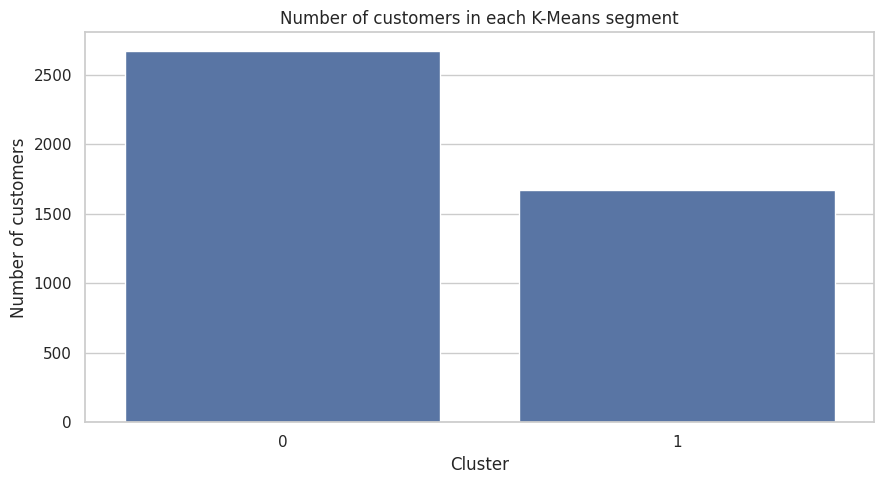

In [17]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=persona_table,
    x="Cluster",
    y="Customers"
)

plt.title("Number of customers in each K-Means segment")
plt.xlabel("Cluster")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

In [18]:
rfm.to_csv(
    "customer_segments.csv",
    index=False
)

persona_table.to_csv(
    "customer_personas.csv",
    index=False
)

results.to_csv(
    "clustering_evaluation.csv",
    index=False
)

print("Saved files:")
print("1. customer_segments.csv")
print("2. customer_personas.csv")
print("3. clustering_evaluation.csv")

Saved files:
1. customer_segments.csv
2. customer_personas.csv
3. clustering_evaluation.csv
